Cell 1: Load both resolutions and show the filtering report.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = Path("..") if Path("../data").exists() else Path(".")
PROC = ROOT / "data/processed"
panels, cells, reports = {}, {}, {}
for res in (6, 7):
    p = PROC / f"panel_h3r{res}_month.parquet"
    if p.exists():
        panels[res] = pd.read_parquet(p)
        cells[res] = gpd.read_parquet(PROC / f"cells_h3r{res}.parquet")
        reports[res] = json.loads((PROC / f"panel_h3r{res}_report.json").read_text())
print("Loaded resolutions:", list(panels))
print(json.dumps(reports[7]["filtering"], indent=2, default=str)[:1500])

Loaded resolutions: [6, 7]
{
  "calls_in_window": 69465,
  "dropped_repeat": 591,
  "dropped_low_precision": 498,
  "dropped_default_geocode": 309,
  "default_geocode_points": [
    {
      "Latitude": 29.1685,
      "Longitude": -81.6427,
      "n": 60
    },
    {
      "Latitude": 29.1783,
      "Longitude": -81.709,
      "n": 18
    },
    {
      "Latitude": 26.2773,
      "Longitude": -81.7042,
      "n": 14
    },
    {
      "Latitude": 28.7095,
      "Longitude": -81.4663,
      "n": 14
    },
    {
      "Latitude": 30.4414,
      "Longitude": -86.6584,
      "n": 14
    },
    {
      "Latitude": 29.0399,
      "Longitude": -81.6402,
      "n": 14
    },
    {
      "Latitude": 30.462,
      "Longitude": -86.6494,
      "n": 13
    },
    {
      "Latitude": 30.415,
      "Longitude": -86.7862,
      "n": 13
    },
    {
      "Latitude": 29.7549,
      "Longitude": -84.8617,
      "n": 13
    },
    {
      "Latitude": 30.4024,
      "Longitude": -86.9478,
      "n": 12
  

Cell 2: How sparse is each resolution? “Active cells” are hexagons with at least one conflict in the whole window. The key number is % of cell-months above zero among active cells.

In [2]:
rows = []
for res, pn in panels.items():
    per_cell = pn.groupby("cell")["n_conflict"].sum()
    active = per_cell[per_cell > 0].index
    pa = pn[pn["cell"].isin(active)]
    rows.append({
        "res": res,
        "cells": pn["cell"].nunique(),
        "cells_with_any_conflict": len(active),
        "% cell-months > 0 (all cells)": round(100 * (pn["n_conflict"] > 0).mean(), 2),
        "% cell-months > 0 (active cells)": round(100 * (pa["n_conflict"] > 0).mean(), 2),
        "mean per active cell-month": round(pa["n_conflict"].mean(), 3),
        "max in one cell-month": int(pn["n_conflict"].max()),
    })
display(pd.DataFrame(rows).set_index("res"))
for res, pn in panels.items():
    vc = pn["n_conflict"].clip(upper=5).value_counts().sort_index()
    vc.index = [str(i) if i < 5 else "5+" for i in vc.index]
    print(f"res {res}: cell-months by conflict count\n{vc.to_string()}\n")

,cells,cells_with_any_conflict,% cell-months > 0 (all cells),% cell-months > 0 (active cells),mean per active cell-month,max in one cell-month
res,,,,,,
6,4468,1466,2.40,7.32,0.142,28
7,30676,3702,0.47,3.90,0.056,20


res 6: cell-months by conflict count
0     619228
1       9197
2       2932
3       1314
4        694
5+      1091

res 7: cell-months by conflict count
0     4335498
1       15346
2        3189
3        1021
4         498
5+        440



Cell 3: Map of conflict events per hexagon over the whole window. Grey hexagons are in the universe but had zero conflicts. The log colour scale keeps hotspots from washing everything else out.

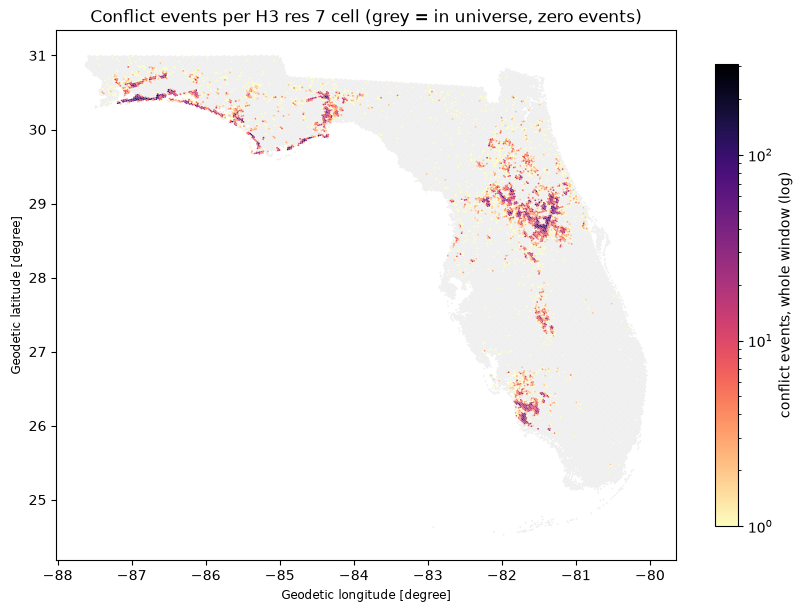

In [3]:
ct = cells[7]
fig, ax = plt.subplots(figsize=(10, 10))
ct[ct["n_conflict_total"] == 0].plot(ax=ax, color="#eeeeee", linewidth=0)
hot = ct[ct["n_conflict_total"] > 0]
hot.plot(ax=ax, column="n_conflict_total", cmap="magma_r", norm=LogNorm(vmin=1, vmax=hot["n_conflict_total"].max()),
         legend=True, linewidth=0, legend_kwds={"shrink": 0.6, "label": "conflict events, whole window (log)"})
ax.set_title("Conflict events per H3 res 7 cell (grey = in universe, zero events)")
ax.set_aspect("equal"); plt.show()

Cell 4: Statewide conflicts per month, coloured by split. It shows the October peaks and the 2023 and 2025 highs, and which ones fall in train, validation or test.

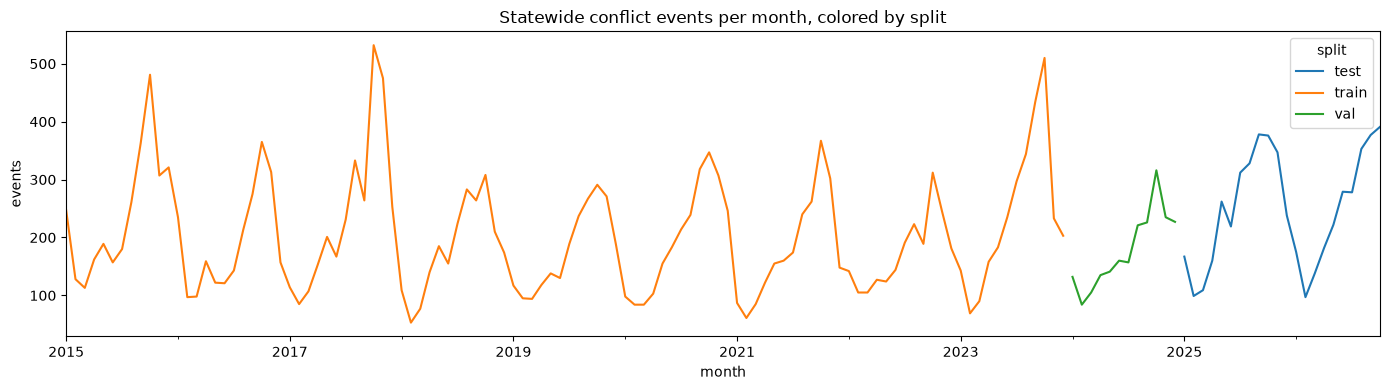

In [4]:
pn = panels[7]
monthly = pn.groupby(["month", "split"])["n_conflict"].sum().unstack()
ax = monthly.plot(figsize=(14, 4), title="Statewide conflict events per month, colored by split")
ax.set_ylabel("events"); plt.tight_layout(); plt.show()

Cell 5: How concentrated are conflicts? If a small share of hexagons holds most events, the model is mostly about finding hotspots, which affects how we evaluate it.

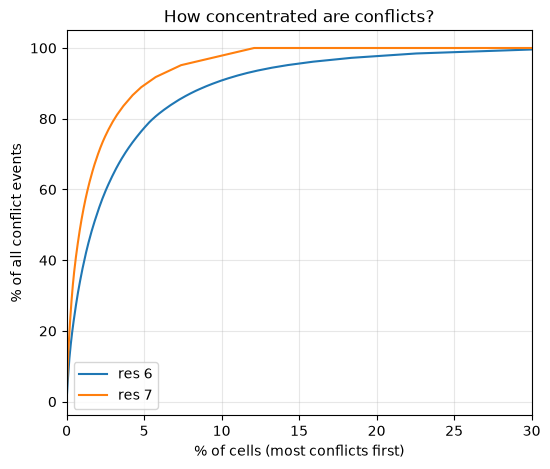

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for res, pn in panels.items():
    s = pn.groupby("cell")["n_conflict"].sum().sort_values(ascending=False)
    ax.plot(np.arange(1, len(s) + 1) / len(s) * 100, s.cumsum() / s.sum() * 100, label=f"res {res}")
ax.set_xlabel("% of cells (most conflicts first)"); ax.set_ylabel("% of all conflict events")
ax.set_xlim(0, 30); ax.grid(alpha=0.3); ax.legend(); ax.set_title("How concentrated are conflicts?")
plt.show()

Cell 6: Conflicts by FWC range level. The “outside” row is conflicts in hexagons outside FWC’s mapped range, which is a sign bears are spreading beyond it.

In [6]:
ct = cells[7]
by_range = ct.groupby("range_label").agg(cells=("cell", "size"), conflicts=("n_conflict_total", "sum"))
by_range["conflicts_per_cell"] = (by_range["conflicts"] / by_range["cells"]).round(2)
by_range["% of conflicts"] = (100 * by_range["conflicts"] / by_range["conflicts"].sum()).round(1)
display(by_range.sort_values("conflicts_per_cell", ascending=False))

,cells,conflicts,conflicts_per_cell,% of conflicts
range_label,,,,
outside,213,1110,5.21,3.8
frequent,8639,27082,3.13,91.5
common,6672,1026,0.15,3.5
occasional,10421,330,0.03,1.1
rare,4731,45,0.01,0.2
